In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded.")

Libraries loaded.


In [6]:
df = pd.read_csv('customer_credit_risk_dataset_2.csv')

print("First 5 rows:")
display(df.head())

print("Shape:", df.shape)

First 5 rows:


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,CR200001,35.0,Female,North,Graduate,Unemployed,271636.67,323669.82,Home,548.0,0,23,74.94,2025-04-18,0
1,CR200002,23.0,Male,North,Graduate,Salaried,327326.24,128971.66,Home,713.0,0,31,41.68,2018-06-21,0
2,CR200003,45.0,Male,South,Post-Graduate,Salaried,1268961.63,984912.66,Home,681.0,0,15,61.60,2024-06-20,0
3,CR200004,NaN,Male,South,Post-Graduate,Salaried,801155.77,324565.35,Car,722.0,4,23,37.15,2019-12-28,0
4,CR200005,60.0,Female,South,Graduate,Salaried,1112876.54,1004940.47,Education,666.0,2,26,29.48,2020-06-13,1


Shape: (1000, 15)


In [7]:
# Get info about data types and missing values
print("Dataset Info:")
df.info()

# Get statistical summary of numeric columns
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1000 non-null   object 
 1   age                970 non-null    float64
 2   gender             975 non-null    object 
 3   region             1000 non-null   object 
 4   education_level    1000 non-null   object 
 5   employment_type    978 non-null    object 
 6   annual_income      980 non-null    float64
 7   loan_amount        982 non-null    float64
 8   loan_purpose       1000 non-null   object 
 9   credit_score       972 non-null    float64
 10  repayment_history  1000 non-null   int64  
 11  transaction_count  1000 non-null   int64  
 12  spending_ratio     978 non-null    float64
 13  join_date          1000 non-null   object 
 14  default_flag       1000 non-null   int64  
dtypes: float64(5), int64(3), object(7)
memory usage: 117.3+ KB


,age,annual_income,loan_amount,credit_score,repayment_history,transaction_count,spending_ratio,default_flag
count,970.000000,9.800000e+02,9.820000e+02,972.000000,1000.000000,1000.000000,978.000000,1000.000000
mean,42.132990,6.066049e+05,3.549286e+05,650.198560,1.919000,24.910000,51.441258,0.205000
std,12.768958,6.672737e+05,4.592035e+05,95.604579,1.438231,5.070464,59.999933,0.403904
min,19.000000,2.270465e+04,1.500000e+04,275.000000,0.000000,10.000000,1.000000,0.000000
25%,33.000000,2.706036e+05,1.241820e+05,589.000000,1.000000,21.000000,20.110000,0.000000
50%,42.000000,4.277496e+05,2.371219e+05,654.000000,2.000000,25.000000,37.035000,0.000000
75%,51.000000,7.114502e+05,4.278869e+05,715.000000,3.000000,29.000000,66.222500,0.000000
max,78.000000,1.025049e+07,7.059829e+06,920.000000,9.000000,43.000000,629.680000,1.000000



Missing Values:
customer_id           0
age                  30
gender               25
region                0
education_level       0
employment_type      22
annual_income        20
loan_amount          18
loan_purpose          0
credit_score         28
repayment_history     0
transaction_count     0
spending_ratio       22
join_date             0
default_flag          0
dtype: int64


In [8]:
# Separate numerical and categorical columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

# Fill missing numerical values with mean
num_imputer = SimpleImputer(strategy='mean')
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Fill missing categorical values with most frequent (mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

# Verify no missing values are left
print("Missing values after imputation:")
print(df.isnull().sum().sum())

Missing values after imputation:
0


In [9]:
def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower, lower, df[column])
    df[column] = np.where(df[column] > upper, upper, df[column])
    return df

# Apply outlier capping on important numeric columns
outlier_cols = ['annual_income', 'loan_amount', 'credit_score', 'spending_ratio']
for col in outlier_cols:
    df = cap_outliers(df, col)

print("Outliers handled.")

Outliers handled.


In [10]:
# Convert join_date to datetime format
df['join_date'] = pd.to_datetime(df['join_date'])

# Extract Year, Month, and Day from the date column
df['join_year'] = df['join_date'].dt.year
df['join_month'] = df['join_date'].dt.month
df['join_day'] = df['join_date'].dt.day

# Drop the original date column
df = df.drop('join_date', axis=1)

print("Date features extracted.")
display(df[['join_year', 'join_month', 'join_day']].head())

Date features extracted.


,join_year,join_month,join_day
0,2025,4,18
1,2018,6,21
2,2024,6,20
3,2019,12,28
4,2020,6,13


In [11]:
# Label Encoding for binary ordinal columns
le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])
df['education_level'] = le.fit_transform(df['education_level'])

df = pd.get_dummies(df, columns=['region', 'employment_type', 'loan_purpose'], drop_first=True)

print("Encoding done. New shape:", df.shape)
display(df.head())

Encoding done. New shape: (1000, 23)


,customer_id,age,gender,education_level,annual_income,loan_amount,credit_score,repayment_history,transaction_count,spending_ratio,...,join_day,region_North,region_South,region_West,employment_type_Self-Employed,employment_type_Unemployed,loan_purpose_Car,loan_purpose_Education,loan_purpose_Home,loan_purpose_Other
0,CR200001,35.00000,0,0,271636.67,323669.820,548.0,0.0,23.0,74.94,...,18,True,False,False,False,True,False,False,True,False
1,CR200002,23.00000,1,0,327326.24,128971.660,713.0,0.0,31.0,41.68,...,21,True,False,False,False,False,False,False,True,False
2,CR200003,45.00000,1,1,1268961.63,874989.225,681.0,0.0,15.0,61.60,...,20,False,True,False,False,False,False,False,True,False
3,CR200004,42.13299,1,1,801155.77,324565.350,722.0,4.0,23.0,37.15,...,28,False,True,False,False,False,True,False,False,False
4,CR200005,60.00000,0,0,1112876.54,874989.225,666.0,2.0,26.0,29.48,...,13,False,True,False,False,False,False,True,False,False


In [12]:
# Binning annual_income into Low, Medium, High groups
df['income_group'] = pd.cut(df['annual_income'], bins=3, labels=['Low', 'Medium', 'High'])
df['income_group'] = le.fit_transform(df['income_group'])

df['credit_flag'] = np.where(df['credit_score'] > 700, 1, 0)

print("Binning done.")
display(df[['annual_income', 'income_group', 'credit_score', 'credit_flag']].head())

Binning done.


,annual_income,income_group,credit_score,credit_flag
0,271636.67,1,548.0,0
1,327326.24,1,713.0,1
2,1268961.63,0,681.0,0
3,801155.77,2,722.0,1
4,1112876.54,0,666.0,0


In [13]:
# Apply StandardScaler on numeric columns
scale_cols = ['age', 'annual_income', 'loan_amount', 'credit_score', 
              'repayment_history', 'transaction_count', 'spending_ratio']

scaler = StandardScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

print("Scaling done.")
display(df[scale_cols].head())

Scaling done.


,age,annual_income,loan_amount,credit_score,repayment_history,transaction_count,spending_ratio
0,-5.674848e-01,-0.762007,0.054502,-1.107826,-1.334946,-0.376880,0.859828
1,-1.522178e+00,-0.603446,-0.751447,0.673172,-1.334946,1.201674,-0.142023
2,2.280930e-01,2.077614,2.336677,0.327766,-1.334946,-1.955434,0.458003
3,5.652920e-16,0.745659,0.058209,0.770318,1.447641,-0.376880,-0.278475
4,1.421460e+00,1.633202,2.336677,0.165858,0.056347,0.215078,-0.509509


In [14]:
# Create new features from existing columns
df['debt_to_income'] = df['loan_amount'] / (df['annual_income'] + 1)
df['avg_monthly_trans'] = df['transaction_count'] / 6
df['spending_to_income'] = df['spending_ratio'] / (df['annual_income'] + 1)

print("New features created.")
display(df[['debt_to_income', 'avg_monthly_trans', 'spending_to_income']].head())

New features created.


,debt_to_income,avg_monthly_trans,spending_to_income
0,0.229008,-0.062813,3.612828
1,-1.894939,0.200279,-0.358143
2,0.759250,-0.325906,0.148818
3,0.033345,-0.062813,-0.159524
4,0.887390,0.035846,-0.193494


In [15]:
pt = PowerTransformer(method='yeo-johnson')
df[['loan_amount', 'annual_income']] = pt.fit_transform(df[['loan_amount', 'annual_income']])

print("Power transformation applied.")
display(df[['loan_amount', 'annual_income']].head())

Power transformation applied.


,loan_amount,annual_income
0,0.345750,-0.804924
1,-0.777105,-0.533147
2,1.784588,1.667249
3,0.349650,0.946470
4,1.784588,1.462342


Final Dataset Shape: (1000, 28)

Final Columns:
['customer_id', 'age', 'gender', 'education_level', 'annual_income', 'loan_amount', 'credit_score', 'repayment_history', 'transaction_count', 'spending_ratio', 'default_flag', 'join_year', 'join_month', 'join_day', 'region_North', 'region_South', 'region_West', 'employment_type_Self-Employed', 'employment_type_Unemployed', 'loan_purpose_Car', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Other', 'income_group', 'credit_flag', 'debt_to_income', 'avg_monthly_trans', 'spending_to_income']


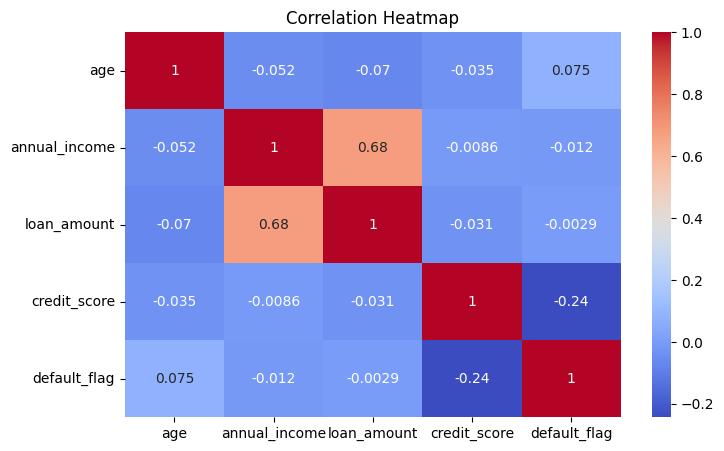

File saved as final_credit_risk_dataset.csv


In [16]:
# Check final shape of the dataset
print("Final Dataset Shape:", df.shape)
print("\nFinal Columns:")
print(df.columns.tolist())

# Create a correlation heatmap to see which features affect default_flag
plt.figure(figsize=(8,5))
sns.heatmap(df[['age', 'annual_income', 'loan_amount', 'credit_score', 'default_flag']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# Save the cleaned dataset to a new CSV file
df.to_csv('final_credit_risk_dataset.csv', index=False)
print("File saved as final_credit_risk_dataset.csv")